In [1]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '3'
import numpy as np 
import scipy as sp
import matplotlib.pyplot as plt
import pyForwardFolding as pyFF
import jax
import nugget
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
from math import inf
import pandas as pd
import torch
from nugget.samplers.sim_weights import event_arrays, generation_params, get_simulation_weights, get_ranged_simulation_weights

In [11]:
device = 'cuda:0'
signal_sampler = nugget.samplers.range_sampler.RangeSampler(
    device=device,
    E_min=1e2,
    E_max=1e6,
    energy_dist='log_uniform',
    injection_radius=1100,
    chunk_size=10000,
    seed=1,  # same events every time the notebook runs
)

num_events_total = int(1e5)
signal_events = signal_sampler.sample_events(num_events_total)
ev = event_arrays(signal_events)
xsec = nugget.losses.effective_area.CrossSection()
transmission = nugget.losses.effective_area.TransmissionProb()
sim_weights = get_simulation_weights(
    ev['energy'], ev['cos_zenith'],
    xsec=xsec, transmission=transmission, batched=True, column_depth=ev['column_depth'],
    **generation_params(signal_sampler),
)
sim_weights = sim_weights.cpu().numpy()

In [4]:
for key in ev.keys():
    ev[key] = ev[key].cpu().numpy()

In [6]:
# save the event dictionary to a file
np.savez('signal_events.npz', **ev)


In [37]:
resolutions = torch.load('analysis_notebook_resolutions.pt')

In [56]:
resolutions.keys()

dict_keys(['initial hexagonal', 'optimised_nfold', 'optimised_dynamic', 'large'])

In [38]:
event_energies = ev['energy'].cpu().numpy()
event_zenith = ev['zenith'].cpu().numpy()

energy_res = resolutions['optimised_nfold']['energy'].cpu().numpy()
zenith_res = resolutions['optimised_nfold']['zenith'].cpu().numpy()
# according to resolution sample a random energy and zenith centered around the true energy and zenith

#filter out events with a relative energy resolution greater than 1.0
def prepare_data(event_energies, event_zenith, energy_res, zenith_res, sim_weights):    
    valid_events = np.abs(energy_res / event_energies) < 1.0
    copy_event_energies = event_energies[valid_events]
    copy_event_zenith = event_zenith[valid_events]
    copy_energy_res = energy_res[valid_events]
    copy_zenith_res = zenith_res[valid_events]
    copy_sim_weights = sim_weights[valid_events]

    reco_energy = np.random.normal(copy_event_energies, copy_energy_res)
    reco_zenith = np.random.normal(copy_event_zenith, copy_zenith_res)
    reco_energy_mask = reco_energy > 1e2
    reco_energy = reco_energy[reco_energy_mask]
    reco_zenith = reco_zenith[reco_energy_mask]
    copy_sim_weights = copy_sim_weights[reco_energy_mask]
    copy_event_energies = copy_event_energies[reco_energy_mask]
    copy_event_zenith = copy_event_zenith[reco_energy_mask]
    
    return {"dataset": {
        "log10_reco_energy": jnp.log10(jnp.asarray(reco_energy)),
        "cos_reco_zenith": jnp.cos(jnp.asarray(reco_zenith)),
        "baseline_weight": jnp.asarray(copy_sim_weights),
        "true_energy": jnp.asarray(copy_event_energies),
        "true_zenith": jnp.asarray(copy_event_zenith),
    }}

In [ ]:
# n = int(5e6)
# event_energies = 10 ** np.random.uniform(2, 8, size=n)
# event_zenith   = np.arccos(np.random.uniform(-1, 1, size=n))

# reco_energy = 10 ** (np.log10(event_energies) + np.random.normal(0, 0.2, size=n))
# reco_zenith = np.arccos(
#     np.clip(np.cos(event_zenith) + np.random.normal(0, 0.05, size=n), -1, 1)
# )
# baseline_weights = event_energies * np.log(10) * 6 / n * 1e5

# data = {
#     "dataset": {
#         "log10_reco_energy": jnp.log10(jnp.asarray(reco_energy)),
#         "cos_reco_zenith":  jnp.cos(jnp.asarray(reco_zenith)),
#         "baseline_weight":  jnp.asarray(baseline_weights),
#         "true_energy":      jnp.asarray(event_energies),
#         "true_zenith":      jnp.asarray(event_zenith),
#     }
# }

/tmp/ipykernel_942310/2124373869.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0, 0.5, 'Weighted Counts')

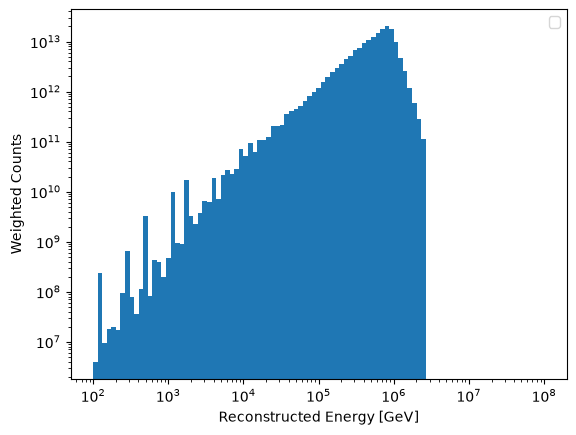

In [15]:
fig, ax = plt.subplots()
h = ax.hist(reco_energy, bins=np.logspace(2, 8, 100), weights=copy_sim_weights)
plt.legend()
plt.loglog()
plt.xlabel("Reconstructed Energy [GeV]")
plt.ylabel("Weighted Counts")

In [22]:
config = '../other/pyFF_config_new.yaml'
ana = pyFF.config.analysis_from_config(config)
params, priors = pyFF.config.params_from_config(config)

In [24]:
obs, ssq = ana.evaluate(data,params)

In [25]:
cobs, cssq = ana.evaluate_per_component(data,params)

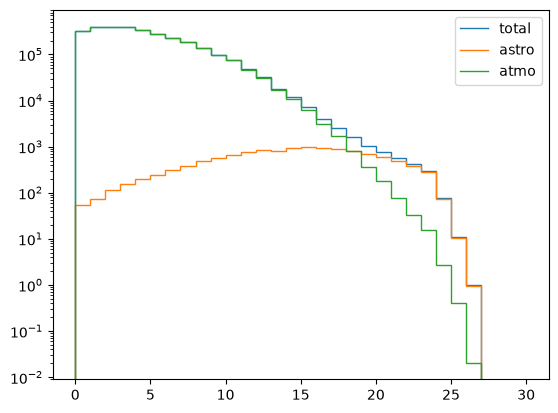

In [26]:
plt.stairs(obs["det1"].sum(axis=1),label="total")
plt.stairs(cobs["det1"]["astro"].sum(axis=1),label="astro")
plt.stairs(cobs["det1"]["atmo"].sum(axis=1),label="atmo")
plt.legend()
plt.yscale("log")

In [27]:
llh = pyFF.likelihood.PoissonLikelihood(ana,priors)
mini = pyFF.minimizer.ScipyMinimizer(llh)

In [ ]:
mini.minimize(obs,data)

(  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
   success: True
    status: 0
       fun: 2473.326797160099
         x: [ 2.000e+00  1.440e+00  1.000e+00]
       nit: 1
       jac: [ 1.849e-12  6.512e-13  2.657e-10]
      nfev: 3
      njev: 3
  hess_inv: <3x3 LbfgsInvHessProduct with dtype=float64>,
 {'astro_index': np.float64(2.0),
  'astro_norm': np.float64(1.44),
  'atmo_norm': np.float64(1.0000000000000002)},
 np.float64(2473.326797160099))

In [ ]:
norms = np.linspace(0,3,11)
llhs = []
for norm in norms:
    res = mini.minimize(obs,data,fixed_pars={"astro_norm":norm})
    llhs.append(res[2])
llhs = np.asarray(llhs)
dllhs = 2*(llhs-np.min(llhs))

Text(0, 0.5, '-2DeltaLLH')

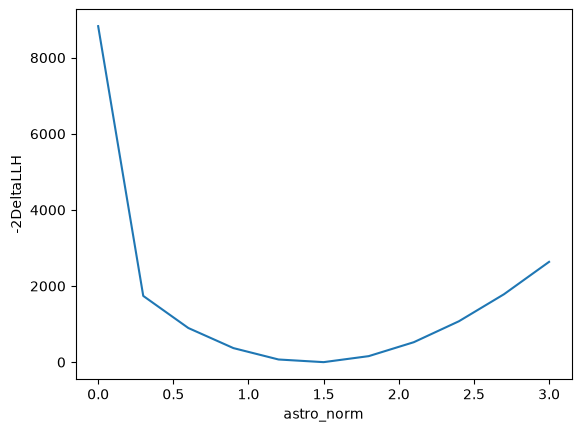

In [31]:
plt.plot(norms,dllhs)
plt.xlabel("astro_norm")
plt.ylabel("-2DeltaLLH")

Evaluating for geometry: initial hexagonal
Evaluating for geometry: optimised_nfold
Evaluating for geometry: optimised_dynamic
Evaluating for geometry: large


(0.0, 9.0)

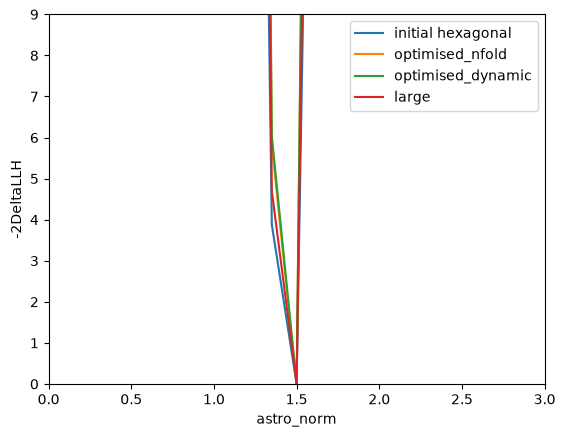

In [46]:
config = '../other/pyFF_config_new.yaml'


for key in resolutions.keys():
    print(f"Evaluating for geometry: {key}")
    energy_res = resolutions[key]['energy'].cpu().numpy()
    zenith_res = resolutions[key]['zenith'].cpu().numpy()

    data = prepare_data(event_energies, event_zenith, energy_res, zenith_res, sim_weights)
    ana = pyFF.config.analysis_from_config(config)
    params, priors = pyFF.config.params_from_config(config)
    obs, ssq = ana.evaluate(data,params)

    llh = pyFF.likelihood.PoissonLikelihood(ana,priors)
    mini = pyFF.minimizer.ScipyMinimizer(llh)
    mini.minimize(obs,data)
    norms = np.linspace(0,3,11)
    llhs = []
    for norm in norms:
        res = mini.minimize(obs,data,fixed_pars={"astro_norm":norm})
        llhs.append(res[2])
    llhs = np.asarray(llhs)
    dllhs = 2*(llhs-np.min(llhs))
    plt.plot(norms,dllhs,label=key)
    
plt.xlabel("astro_norm")
plt.ylabel("-2DeltaLLH")
plt.legend()
# plot only in the range where dllhs <= 9
plt.xlim(0, 3)
plt.ylim(0, 9)
# plt.yscale("log")